<a href="https://colab.research.google.com/github/bsheese/387/blob/main/23_language/23_2_Pretrained_Transformers/23_2_2_Fine_Tuning_DistilBERT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Language: Part 5
## Fine-Tuning DistilBERT

---

## What This Notebook Is About

23_2_1 used a sentiment model that someone else had fine-tuned, on short sentences from movie reviews. This notebook does the fine-tuning ourselves: it takes the pretrained DistilBERT from 23_0 and 23_1, which has never been trained to classify anything, adds a new last layer, and trains it on our 2,000 IMDB training reviews. It is the text version of 22_1_1's transfer learning, and the training loop is unit 21's.

As always, the result only means something next to a baseline, so we start with one that involves no neural network at all.

**What you will learn:**
1. A strong simple baseline for text: word counts weighted by **TF-IDF**, with logistic regression
2. How a pretrained language model becomes a classifier: a new **classification head** on top
3. Fine-tuning every weight of the network with unit 21's training loop
4. How the result compares with the baseline and with 23_2_1's ready-made model
5. Reading the mistakes: which reviews the fine-tuned model gets wrong, and why

**This notebook needs a GPU.** On Colab's GPU (Runtime → Change runtime type → T4 GPU) the fine-tuning takes about a minute and a half and the rest of the notebook seconds. On Colab's CPU the fine-tuning would take about two hours. If Colab won't give you a GPU, switch to your partner's Colab account. If neither of you can get one, run Section 1 (it's fast) and read the saved outputs for the rest: the notebook is saved with all of its outputs.

In [1]:
import os
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from transformers import AutoModelForSequenceClassification, AutoTokenizer, pipeline

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

DATA_URL = 'https://raw.githubusercontent.com/bsheese/387/main/data/'

def fetch(name):
    # Download a file from the course's data folder, unless it is already here.
    # It saves to a temporary name first, so a download that fails partway doesn't leave a broken file behind.
    if not os.path.exists(name):
        urllib.request.urlretrieve(DATA_URL + name, name + '.part')
        os.replace(name + '.part', name)
    return name

reviews = pd.read_csv(fetch('imdb_reviews.csv'))
train = reviews[reviews['split'] == 'train'].reset_index(drop=True)
val = reviews[reviews['split'] == 'val'].reset_index(drop=True)
test = reviews[reviews['split'] == 'test'].reset_index(drop=True)
print(f'train {len(train)}, val {len(val)}, test {len(test)} reviews;',
      f"fraction positive: {train['label'].mean():.2f} / {val['label'].mean():.2f} / {test['label'].mean():.2f}")

device: cpu
train 2000, val 1000, test 2000 reviews; fraction positive: 0.50 / 0.50 / 0.50


These are the same reviews as in 23_0 (label 1 is positive, 0 is negative), split into 2,000 for training, 1,000 for validation and 2,000 for testing. Every split is half positive, so the most-common-answer baseline from 19_1_1 scores 0.50.

---

## Section 1: A Baseline Without a Neural Network

Before using a 66-million-weight network, it's worth knowing how well a simple method does. A classic one for text works directly on words:

1. **Count the words.** Each review becomes a long row of numbers, one column for every word in the training reviews' vocabulary, holding how often that word appears in the review. Word order is thrown away; this is often called a **bag of words**.
2. **Weight the counts by TF-IDF** (term frequency times inverse document frequency). A word that appears in nearly every review, like "the" or "movie", gets a small weight, and a word that appears in only a few reviews gets a larger one, because rare words say more about a particular review.
3. **Fit logistic regression** on those columns (19_1_3's single neuron), so that every word gets a weight: positive for words that push toward a positive review, negative for the opposite.

scikit-learn's `TfidfVectorizer` does steps 1 and 2. Like every choice in this course, its settings were checked on the validation reviews, and the test reviews are used once.

In [2]:
tfidf = TfidfVectorizer(min_df=2, ngram_range=(1, 2), sublinear_tf=True)   # words and pairs of words seen in at least 2 reviews
X_train = tfidf.fit_transform(train['text'])           # learn the vocabulary from the training reviews only
X_val, X_test = tfidf.transform(val['text']), tfidf.transform(test['text'])
print('columns (words and word pairs):', X_train.shape[1])

baseline = LogisticRegression(C=3, max_iter=2000).fit(X_train, train['label'])
print(f"validation accuracy {baseline.score(X_val, val['label']):.3f}")
print(f"test accuracy       {baseline.score(X_test, test['label']):.3f}")

vocab = np.array(tfidf.get_feature_names_out())
order = np.argsort(baseline.coef_[0])
print('\nmost negative words:', ', '.join(vocab[order[:12]]))
print('most positive words:', ', '.join(vocab[order[-12:][::-1]]))

columns (words and word pairs): 56492
validation accuracy 0.879
test accuracy       0.855

most negative words: bad, worst, the worst, no, awful, nothing, terrible, horrible, any, even, don, minutes
most positive words: excellent, great, well, love, best, perfect, one of, fun, wonderful, the best, very, life


With words and pairs of words that appear in at least two training reviews, each review becomes a row of 56,492 numbers, almost all of them 0. Logistic regression on those columns gets 0.879 of the validation reviews right and 0.855 of the test reviews, far above the 0.50 of always saying "positive". The test accuracy is lower than the validation accuracy partly because the settings were chosen on the validation reviews, which makes the validation score a little optimistic, as 19_1_1 showed.

The words with the most negative weights are what you'd expect ("bad", "worst", "awful", "terrible", "horrible"), along with "minutes", which probably comes from complaints about time wasted watching a film. The most positive include "excellent", "great", "perfect" and "wonderful", and also pairs like "one of" (as in "one of the best"). This baseline knows nothing about grammar or word order beyond pairs of words. It can't tell "not good" in "not good at all" from "not good, but great", and that is what a model that reads whole sentences might add.

---

## Section 2: A Pretrained Model with a New Head

For 19_0 we took a network pretrained on ImageNet and replaced its last layer with a new one for our four breeds. The same move works for text. `AutoModelForSequenceClassification` loads the pretrained DistilBERT from 23_0 and puts a new **classification head** on top: a small network that takes the final vector of the `[CLS]` token (23_0_1), the token that DistilBERT places at the start of every text, and turns it into two scores, one for negative and one for positive. The head's weights don't exist in the pretrained model, so they start out random, and the library prints a report saying so.

In [3]:
tokenizer = AutoTokenizer.from_pretrained('distilbert-base-uncased')
torch.manual_seed(0)
model = AutoModelForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2).to(device)

head = ['pre_classifier', 'classifier']
n_head = sum(p.numel() for name, p in model.named_parameters() if name.split('.')[0] in head)
print(f'weights in the whole model: {sum(p.numel() for p in model.parameters()):,}')
print(f'weights in the new head:    {n_head:,}')
print(model.pre_classifier, model.classifier, sep='\n')

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


weights in the whole model: 66,955,010
weights in the new head:    592,130
Linear(in_features=768, out_features=768, bias=True)
Linear(in_features=768, out_features=2, bias=True)


The report lists two kinds of weights. The ones marked UNEXPECTED were in the pretrained file but aren't used here: they belong to the layer that predicted masked words during pretraining (23_2_1), which a classifier doesn't need. The ones marked MISSING are the new head's, `pre_classifier` and `classifier`, which start random. The head is the same shape as the one in 23_2_1's sentiment model: a linear layer from 768 numbers to 768, and one from 768 to 2. It has 592,130 weights, under 1% of the model's 66,955,010; the rest are the pretrained DistilBERT.

---

## Section 3: Tokens In, Batches Out

The tokenizer turns every review into token IDs (23_0_1). Reviews are cut off at 256 tokens to keep training fast. 23_0_1 found that about 41% of the reviews are longer than that, so for those the model sees only the beginning; Section 6 checks whether that matters. Shorter reviews are padded, and the **attention mask** marks which positions are real tokens (23_1_1).

In [4]:
MAX_TOKENS = 256

def to_batches(df, batch_size, shuffle=False):
    enc = tokenizer(list(df['text']), truncation=True, max_length=MAX_TOKENS, padding='max_length', return_tensors='pt')
    data = torch.utils.data.TensorDataset(enc['input_ids'], enc['attention_mask'], torch.tensor(df['label'].values))
    return torch.utils.data.DataLoader(data, batch_size=batch_size, shuffle=shuffle)

train_loader = to_batches(train, 16, shuffle=True)
val_loader = to_batches(val, 64)
test_loader = to_batches(test, 64)
ids, mask, labels = next(iter(train_loader))
print('one batch:', tuple(ids.shape), tuple(mask.shape), tuple(labels.shape))

one batch: (16, 256) (16, 256) (16,)


---

## Section 4: Fine-Tuning

The training loop is unit 21's, with three differences.

- **Every weight is trained.** In 19_0 the pretrained network was frozen, and in 22_1_1 only its last block was unfrozen. Here all 66 million weights change. That is the usual way to fine-tune a language model of this size, and it works because the changes are small: the learning rate, 0.00003, is a thirtieth of the 0.001 used in unit 21, so training adjusts the pretrained weights rather than overwriting them (the same reasoning as 22_1_1's smaller learning rate for pretrained layers).
- **Two epochs.** A pretrained model needs very little training to adapt; more epochs would mostly overfit the 2,000 reviews (21_1_1).
- **The model computes its own loss.** Given the labels, the Hugging Face model returns the cross-entropy loss (19_1_4) along with the scores, so the loop doesn't need a separate `loss_fn`.

After each epoch the loop measures the accuracy on the validation reviews.

In [5]:
def predict_probs(loader):
    # The probability of "positive" for every review in loader
    model.eval()
    probs = []
    with torch.no_grad():
        for ids, mask, _ in loader:
            scores = model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
            probs.append(scores.softmax(dim=1)[:, 1].cpu())
    return torch.cat(probs).numpy()

EPOCHS = 2
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-5)
start = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    total, n = 0.0, 0
    for ids, mask, labels in train_loader:
        out = model(input_ids=ids.to(device), attention_mask=mask.to(device), labels=labels.to(device))
        optimizer.zero_grad()
        out.loss.backward()
        optimizer.step()
        total += out.loss.item() * len(labels)
        n += len(labels)
    val_acc = ((predict_probs(val_loader) > 0.5) == val['label'].values).mean()
    print(f'epoch {epoch}: training loss {total / n:.3f}   validation accuracy {val_acc:.3f}   '
          f'({time.time() - start:.0f} s so far)')

epoch 1: training loss 0.432   validation accuracy 0.868   (285 s so far)


epoch 2: training loss 0.207   validation accuracy 0.883   (1959 s so far)


After one epoch the model gets 0.868 of the validation reviews right, already close to the baseline, and after two epochs 0.883. The training loss halves, from 0.432 to 0.207, so with a third epoch the model would start to fit the training reviews more closely than the validation ones (21_1_1).

The saved times come from a laptop CPU, where the first epoch took 285 seconds; the second took much longer only because other programs were using the computer at the same time. On Colab's T4 GPU an epoch takes about 40 seconds.

---

## Section 5: The Test Reviews

Now the test reviews, used once. For comparison we also run 23_2_1's ready-made sentiment model, which was fine-tuned by Hugging Face on short sentences from a different set of movie reviews (SST-2) and has never seen IMDB, on the same 2,000 test reviews, cut off at the same 256 tokens.

In [6]:
test_probs = predict_probs(test_loader)
test_pred = (test_probs > 0.5).astype(int)
fine_tuned_acc = (test_pred == test['label'].values).mean()

ready_made = pipeline('sentiment-analysis', model='distilbert-base-uncased-finetuned-sst-2-english',
                      device=0 if device == 'cuda' else -1)
out = ready_made(list(test['text']), truncation=True, max_length=MAX_TOKENS, batch_size=64)
ready_made_acc = np.mean([(o['label'] == 'POSITIVE') == bool(y) for o, y in zip(out, test['label'])])

print(f"{'always say positive':40} {0.5:.3f}")
print(f"{'TF-IDF + logistic regression':40} {baseline.score(X_test, test['label']):.3f}")
print(f"{'ready-made SST-2 model (23_2_1)':40} {ready_made_acc:.3f}")
print(f"{'our fine-tuned DistilBERT':40} {fine_tuned_acc:.3f}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

always say positive                      0.500
TF-IDF + logistic regression             0.855
ready-made SST-2 model (23_2_1)          0.890
our fine-tuned DistilBERT                0.880


Our fine-tuned DistilBERT gets 0.880 of the test reviews right, 2.5 points better than the TF-IDF baseline (0.855). The ready-made model from 23_2_1 does slightly better than ours, 0.890, even though it was fine-tuned on a different set of reviews. It was trained by Hugging Face on 67,000 labeled sentences, compared with our 2,000 reviews.

How much these differences mean depends on how many reviews they come from. With 2,000 test reviews, a difference of 0.01 is 20 reviews, and a different random choice of test reviews could move each accuracy by about that much. So the fair summary is that our model and the ready-made one are about equally good on these reviews, both are better than the baseline, and the baseline, which takes a second to train on a CPU, is not far behind either of them. That's worth knowing before reaching for a large model.

---

## Section 6: Reading the Mistakes

The confusion matrix (19_1_2) shows which way the mistakes go.

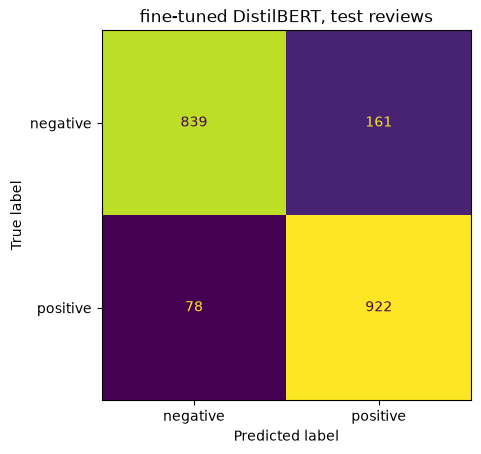

accuracy on reviews of up to 256 tokens: 0.905  (1219 reviews)
accuracy on longer reviews (cut off):  0.843  (781 reviews)


In [7]:
cm = confusion_matrix(test['label'], test_pred)
ConfusionMatrixDisplay(cm, display_labels=['negative', 'positive']).plot(colorbar=False)
plt.title('fine-tuned DistilBERT, test reviews')
plt.show()

test = test.assign(prob_positive=test_probs, predicted=test_pred,
                   n_tokens=[len(tokenizer(t)['input_ids']) for t in test['text']])
test['correct'] = test['predicted'] == test['label']
long = test['n_tokens'] > MAX_TOKENS
print(f"accuracy on reviews of up to {MAX_TOKENS} tokens: {test.loc[~long, 'correct'].mean():.3f}  ({(~long).sum()} reviews)")
print(f"accuracy on longer reviews (cut off):  {test.loc[long, 'correct'].mean():.3f}  ({long.sum()} reviews)")

The two kinds of mistake aren't equally common. The model called 161 negative reviews positive and only 78 positive reviews negative, so when it is wrong it leans toward "positive".

The model does better on reviews short enough to read in full: 0.905 on the 1,219 test reviews of up to 256 tokens, against 0.843 on the 781 longer ones that were cut off. Some of that may be because long reviews are harder in themselves, but a review's verdict often comes at the end ("...but in the end I can't recommend it"), and the model never saw the end of those. Using all 512 tokens DistilBERT can take would probably help, but training would take more than twice as long, since attention's cost grows faster than the length of the text (23_1_1).

The most useful thing to do with the mistakes is to read some. The next cell shows the four test reviews the model got wrong with the most confidence, the start of each one.

In [8]:
wrong = test[~test['correct']].copy()
wrong['confidence'] = np.where(wrong['predicted'] == 1, wrong['prob_positive'], 1 - wrong['prob_positive'])
for _, row in wrong.sort_values('confidence', ascending=False).head(4).iterrows():
    truth = 'positive' if row['label'] == 1 else 'negative'
    print(f"really {truth}, model {row['confidence']:.3f} sure it was the opposite ({row['n_tokens']} tokens):")
    print('   ', row['text'][:600], '...\n')

really negative, model 0.982 sure it was the opposite (181 tokens):
    I saw Winnie's Heffalump a couple of days ago. A nice story based on well known characters created by A.A.Milne. Although Winnie, Piglet, Tigger and Rabbit are all present in this animated feature, the main character is Roo this time. He befriends with scary Heffalump who proves to be not scary at all and shows everybody that friendship knows no boundaries and everybody wants and deserves to be happy. I love this film and I would love it even more were I 10 or 15 years younger. Alas, I would like to become a kid again to enjoy this Heffalump story much more but all I am left with is a sense of ...

really negative, model 0.981 sure it was the opposite (73 tokens):
    This film is worth seeing since it is a classic in the sense of being the very first full length film released in the process of three demention. It was not very good in its acting or story plot, but can be a great movie quiz question from an historic

Reading them, several of the "mistakes" are hard to call mistakes. The IMDB labels come from the star rating each reviewer gave (4 out of 10 or less is negative, 7 or more is positive), not from the text.

- The first review, of a Winnie-the-Pooh film, says "I love this film", and it is labeled negative; the reviewer presumably gave a low rating because it's a film for children. A person reading only the text would probably call it positive too.
- The second calls the film "worth seeing" as a classic of early 3D but says it "was not very good in its acting or story plot". It's genuinely mixed.
- The third is positive because the film is "so bad" that it is "absolutely hilarious": every sentence uses negative words ("awful, badly acted", "no plot") to praise it. This is the hardest kind of review for any model, and the same problem as the sarcastic sentence in 23_2_1.
- The fourth is a fond, nostalgic review of a children's film from 1974 that also says older kids "will get bored", and it is labeled negative.

So part of the error rate is the model's, and part comes from the labels. The labels are a rule applied to star ratings, and the text doesn't always match the rating. That's true of most real labeled data, and it puts a ceiling on how well any model can score.

---

## Section 7: Other Ways to Do This

**Hugging Face's `Trainer`.** Outside this course, fine-tuning is usually done with the `Trainer` class from `transformers` rather than a hand-written loop. It runs the same steps as the loop in Section 4 (batches, loss, backward, optimizer step, evaluation), and adds things like a learning-rate schedule, saving checkpoints and training on several GPUs. The loop here was written out so that every step is visible, and it's the loop unit 21 built.

**Saving the model.** `model.save_pretrained('my_model')` and `tokenizer.save_pretrained('my_model')` write the fine-tuned model to a folder, and `pipeline('sentiment-analysis', model='my_model')` loads it again as a ready-made model, which is how the SST-2 model in 23_2_1 was shared.

**Freezing instead.** We could have frozen DistilBERT and trained only the head, the feature extraction of 19_0. For text that usually does noticeably worse than fine-tuning everything, because the `[CLS]` vector of a model that was never trained on a classification task doesn't carry much information about sentiment until fine-tuning puts it there.

---

## Summary

- A **bag of words** with **TF-IDF** weights and logistic regression is a strong, fast baseline for text classification. Here it got 0.855 of the test reviews right.
- A classifier is made from a pretrained language model by adding a **classification head** that reads the final vector of the `[CLS]` token. The head starts random.
- Fine-tuning trains every weight, with a small learning rate (0.00003) and few epochs, so the pretrained weights are adjusted rather than replaced.
- Fine-tuned for two epochs on 2,000 reviews, DistilBERT got 0.880 of the test reviews right, against 0.855 for the baseline and 0.890 for the ready-made SST-2 model; with 2,000 test reviews, differences of about 0.01 can't be told apart from chance.
- It leaned toward "positive" (161 negatives called positive, 78 positives called negative) and did worse on reviews cut off at 256 tokens (0.843 against 0.905). Its most confident mistakes were mixed or ironic reviews and labels that came from the star rating rather than the text.

## What's next

DistilBERT reads a whole text and produces one answer about it. The language models behind chatbots work differently: they produce text, one token at a time, each token chosen from a probability distribution over the next token. 23_3_1 opens that up with GPT-2: where the next-token probabilities come from, how a token is picked from them, and how settings like **temperature** change what comes out.